# EDA: What's Cooking

Quick look at the raw Kaggle data before building the graph:
cuisines, recipe sizes, ingredients, data-quality problems, and the first co-occurrence signal.

In [1]:
import json
import math
from collections import Counter
from itertools import combinations

import pandas as pd
import matplotlib.pyplot as plt

with open("../data/raw/train.json", encoding="utf-8") as f:
    recipes = json.load(f)

df = pd.DataFrame(recipes)
df["n_ingredients"] = df["ingredients"].apply(len)
df.head()

,id,cuisine,ingredients,n_ingredients
0,10259,greek,"[romaine lettuce, black olives, grape tomatoes...",9
1,25693,southern_us,"[plain flour, ground pepper, salt, tomatoes, g...",11
2,20130,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, g...",12
3,22213,indian,"[water, vegetable oil, wheat, salt]",4
4,13162,indian,"[black pepper, shallots, cornflour, cayenne pe...",20


## 1. Size and missing values

In [2]:
print("recipes:", len(df))
print("unique ids:", df["id"].nunique())
print("missing values:", df.isna().sum().sum())

recipes: 39774
unique ids: 39774
missing values: 0


## 2. Cuisines

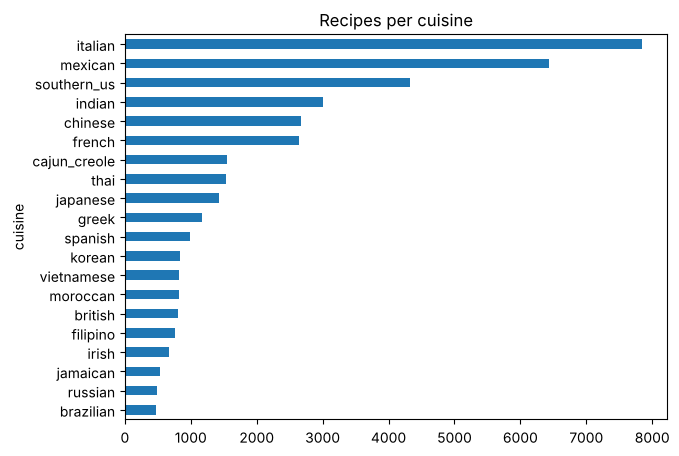

cuisine
italian        0.197063
mexican        0.161865
southern_us    0.108614
Name: count, dtype: float64
biggest / smallest: 16.8


In [3]:
cuisine_counts = df["cuisine"].value_counts()
cuisine_counts.plot(kind="barh", figsize=(7, 5), title="Recipes per cuisine")
plt.gca().invert_yaxis()
plt.show()

print(cuisine_counts.head(3) / len(df))
print("biggest / smallest:", round(cuisine_counts.max() / cuisine_counts.min(), 1))

## 3. Number of ingredients per recipe

count    39774.000000
mean        10.767713
std          4.428978
min          1.000000
25%          8.000000
50%         10.000000
75%         13.000000
max         65.000000
Name: n_ingredients, dtype: float64


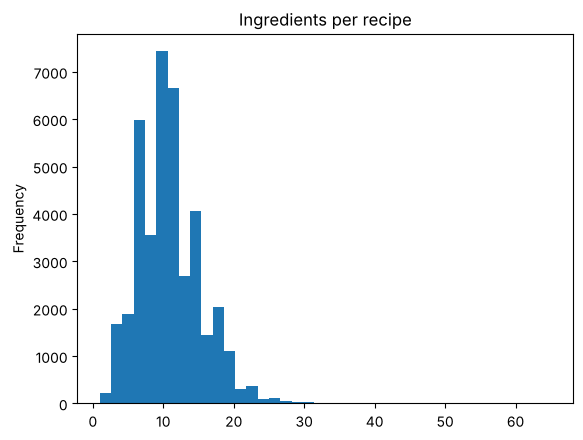

cuisine
irish            9.3
brazilian        9.5
southern_us      9.6
british          9.7
japanese         9.7
french           9.8
italian          9.9
filipino        10.0
greek           10.2
russian         10.2
spanish         10.4
mexican         10.9
korean          11.3
chinese         12.0
jamaican        12.2
thai            12.5
cajun_creole    12.6
vietnamese      12.7
indian          12.7
moroccan        12.9
Name: n_ingredients, dtype: float64

In [4]:
print(df["n_ingredients"].describe())

df["n_ingredients"].plot(kind="hist", bins=40, title="Ingredients per recipe")
plt.show()

df.groupby("cuisine")["n_ingredients"].mean().sort_values().round(1)

## 4. Ingredients

In [5]:
ingredient_counts = Counter(i for lst in df["ingredients"] for i in lst)
freq = pd.Series(ingredient_counts).sort_values(ascending=False)

print("distinct ingredients:", len(freq))
print("used only once:", (freq == 1).sum())
print("used 20 times or more:", (freq >= 20).sum())
print("salt is in", round(freq["salt"] / len(df) * 100), "% of recipes")
freq.head(15)

distinct ingredients: 6714
used only once: 1759
used 20 times or more: 1689
salt is in 45 % of recipes


salt                   18049
olive oil               7972
onions                  7972
water                   7457
garlic                  7380
sugar                   6434
garlic cloves           6237
butter                  4848
ground black pepper     4785
all-purpose flour       4632
pepper                  4438
vegetable oil           4385
eggs                    3388
soy sauce               3296
kosher salt             3113
dtype: int64

## 5. Data quality (to clean)

In [6]:
names = pd.Series(freq.index)

print("with uppercase letters:", (names != names.str.lower()).sum())
print("with a brand symbol ® or ™:", names.str.contains("®|™").sum())
print("with digits (quantities):", names.str.contains(r"\d").sum())
print()
print("examples:", list(names[names.str.contains("®|™|\\d")].head(5)))

with uppercase letters: 499
with a brand symbol ® or ™: 69
with digits (quantities): 40

examples: ['1% low-fat milk', '2% reduced-fat milk', 'Country Crock® Spread', "I Can't Believe It's Not Butter!® Spread", 'Bertolli® Classico Olive Oil']


In [7]:
# the same ingredient written in different ways
freq[[name for name in freq.index if "garlic" in name]].head(8)

garlic                 7380
garlic cloves          6237
minced garlic          1583
garlic powder          1442
large garlic cloves     873
chopped garlic          345
garlic paste            282
garlic salt             240
dtype: int64

## 6. Typical ingredients of each cuisine

In [8]:
# lift = how much more often an ingredient appears in this cuisine than in the whole dataset
rows = df.explode("ingredients").reset_index(drop=True)
table = pd.crosstab(rows["ingredients"], rows["cuisine"])
table = table[table.sum(axis=1) >= 30]          # skip rare ingredients

share_in_cuisine = table / table.sum(axis=0)    # column-wise share
share_overall = table.sum(axis=1) / table.values.sum()
lift = share_in_cuisine.div(share_overall, axis=0)

for cuisine in ["italian", "mexican", "chinese", "indian", "french"]:
    print(f"{cuisine:>8}:", ", ".join(lift[cuisine].sort_values(ascending=False).head(5).index))

 italian: gnocchi, fresh mozzarella, broccoli rabe, marinara sauce, cheese tortellini
 mexican: Mexican beer, mexican chocolate, baked tortilla chips, taco sauce, poblano chilies
 chinese: fermented black beans, chinese rice wine, szechwan peppercorns, Shaoxing wine, chinese black vinegar
  indian: fenugreek, asafoetida powder, fresh curry leaves, urad dal, masala
  french: grated Gruyère cheese, gruyere cheese, cognac, herbes de provence, Grand Marnier


## 7. Which ingredients go together?

In [9]:
common = set(freq[freq >= 20].index)
pairs = Counter()
for lst in df["ingredients"]:
    pairs.update(combinations(sorted(set(lst) & common), 2))

n = len(df)
pair_rows = []
for (a, b), together in pairs.items():
    if together >= 20:
        p_ab = together / n
        pmi = math.log(p_ab / ((freq[a] / n) * (freq[b] / n)))
        pair_rows.append({"a": a, "b": b, "together": together, "npmi": round(pmi / -math.log(p_ab), 2)})
pair_df = pd.DataFrame(pair_rows)

print("Most frequent pairs:")
print(pair_df.sort_values("together", ascending=False).head(8).to_string(index=False))
print()
print("Most associated pairs (NPMI):")
print(pair_df.sort_values("npmi", ascending=False).head(8).to_string(index=False))

Most frequent pairs:
                a     b  together  npmi
           onions  salt      4392  0.09
        olive oil  salt      4177  0.06
             salt water      3960  0.07
           pepper  salt      3844  0.28
           garlic  salt      3749  0.05
all-purpose flour  salt      3079  0.15
             salt sugar      3061  0.02
    garlic cloves  salt      2995  0.02

Most associated pairs (NPMI):
               a                  b  together  npmi
  brown cardamom     green cardamom        27  0.79
        galangal kaffir lime leaves        42  0.73
    garlic paste       ginger paste        70  0.70
active dry yeast         warm water       214  0.70
     ladyfingers         mascarpone        27  0.69
        galangal         lemongrass        65  0.69
           mirin               sake       173  0.68
  green cardamom               mace        24  0.66


## Summary

- 39,774 recipes, 20 cuisines, very unbalanced (Italian + Mexican ≈ 36%).
- About 10 ingredients per recipe; spice-based cuisines use more.
- 6,714 ingredient names, with a long tail: a quarter are used only once.
- Names need cleaning: uppercase, brands, quantities, synonyms (garlic / garlic cloves / minced garlic).
- Each cuisine has clearly typical ingredients, so the cuisine label is a usable ground truth.
- The most *frequent* pairs are generic (salt + onions); the most *associated* pairs (NPMI) are real combinations.
  → The graph should link ingredients by association, not by raw counts.